# Your first quantum programs with Qiskit
### Qiskit Fall Fest · University of Saskatchewan · November 2026

Start with a single qubit. Learn to control its state, interpret measurements, and build entanglement. Finish by making a three-qubit state and investigating what a bit flip does to it.

**No quantum computing background is assumed.** We introduce the small amount of Python and mathematics we need. Work with a partner if coding is new to you.

By the end, you should be able to:

1. Build and draw a quantum circuit using `QuantumCircuit`.
2. Explain the roles of `X`, `H`, `Z`, and `CX` gates.
3. Run an ideal simulation and interpret counts, shots, and bit order.
4. Explain why superposition is different from ordinary randomness.
5. Create Bell and GHZ states, and modify a circuit to test a prediction.

> **Our working rhythm: predict → run → explain → change one thing.**
> These tiny circuits are learning experiments, not demonstrations of computational speedup.

## Before class: open and prepare this notebook

**Browser option:** open [Google Colab](https://colab.research.google.com/), choose **File → Upload notebook**, and upload this `.ipynb` file. A normal CPU runtime is enough. Install the packages using the cell below, then restart the session if Colab asks you to.

**Local option:** install Python 3.11 or 3.12, place the tutorial files in a folder, and use these commands **in a terminal**, from that folder. The environment must be created before it can be activated.

macOS / Linux:
```bash
python3 -m venv .venv
source .venv/bin/activate

python -m pip install "qiskit[visualization]>=2,<3" "numpy>=1.26,<3" "matplotlib>=3.8,<4" "jupyterlab>=4,<5" "ipykernel>=6,<8"

python -m jupyter lab Qiskit_Fall_Fest_80_Minute_Tutorial.ipynb
```

Windows PowerShell (activation is not required):
```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install "qiskit[visualization]>=2,<3" "numpy>=1.26,<3" "matplotlib>=3.8,<4" "jupyterlab>=4,<5" "ipykernel>=6,<8"
.\.venv\Scripts\python.exe -m jupyter lab Qiskit_Fall_Fest_80_Minute_Tutorial.ipynb
```

The next cell is deliberately commented out so **Run All never installs software**. Uncomment it only if your notebook environment needs the packages. `%pip` installs into the active notebook kernel. Restart the kernel after installation, then continue with Section 0.

All exercises run on your computer using Qiskit's ideal simulator. No IBM account, API token, or Qiskit Aer installation is needed. Internet is needed for initial installation; local execution subsequently works offline.

In [1]:
# Run this only when setting up a notebook environment, such as Colab.
# Remove the leading # from the next line if installation is needed.
# %pip install "qiskit[visualization]>=2,<3" "numpy>=1.26,<3" "matplotlib>=3.8,<4"

## 0 · Get oriented 

A **Jupyter notebook** mixes explanation cells with Python code cells.

- Click a code cell and press **Shift + Enter** to run it and move on.
- Run cells from top to bottom. The **kernel** is the Python process that remembers variables.
- A busy indicator means a cell is running. Wait before running the next cell.
- If you change an earlier cell, rerun the cells that depend on it.
- To start fresh, use **Kernel → Restart Kernel and Run All Cells** in JupyterLab. In Colab, the corresponding controls are under **Runtime**.

Saved outputs are included so you can read the notebook even before running it. They are reference results, not evidence that your current kernel has run the cells.

**First prediction:** what will the following cell print? Change the name and run it.

In [3]:
participant = "Abigail"
print("Hello,", participant)
print("One bit has", 2, "possible values: 0 and 1.")

Hello, Abigail
One bit has 2 possible values: 0 and 1.


## 1 · Setup and a little Python

**Qiskit** is a Python toolkit for describing and working with quantum computations. A **circuit** describes operations; a **simulator** calculates what an idealized execution would do.

Run these imports once. If they fail, use the setup instructions above or pair up with someone whose notebook runs.

In [2]:
import sys
import qiskit
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

SEED = 2026
SHOTS = 1024
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})
print("Python:", sys.version.split()[0])
print("Qiskit:", qiskit.__version__)
print("Ready: ideal simulation on this computer.")

Python: 3.14.4
Qiskit: 2.6.2
Ready: ideal simulation on this computer.


### The Python we need

| Python | Meaning |
|---|---|
| `shots = 100` | Store a value in a variable |
| `# a note` | A comment; Python ignores it |
| `print(shots)` | Display a value |
| `qc.x(0)` | Ask circuit `qc` to add an X gate on qubit 0 |
| `[qc]` | A list containing one circuit |
| `counts['0']` | Look up the value associated with key `'0'` |
| `counts.get('1', 0)` | Look up `'1'`; use 0 if it is absent |

Python counts positions starting at **0**. An indented block belongs to the `for` loop or function above it. You can read the later helpers without having to write functions yourself.

In [3]:
example_counts = {"0": 6, "1": 4}  # A dictionary: outcome -> number of occurrences
total = sum(example_counts.values())
print("Total shots:", total)
print("Observed fraction of 1s:", example_counts["1"] / total)

Total shots: 10
Observed fraction of 1s: 0.4


## 2 · One qubit: prepare, flip, measure 

A classical bit has value 0 or 1. A qubit has two **computational basis states**, written $|0\rangle$ and $|1\rangle$. Read $|0\rangle$ aloud as “ket zero”; it is a label for a state.

Our simulated circuits start every qubit in $|0\rangle$. An **X gate** exchanges the basis states:

$$X|0\rangle=|1\rangle,\qquad X|1\rangle=|0\rangle.$$

Circuit diagrams are read **left to right**. A horizontal wire is a qubit. A gate acts where it appears on that wire.

**Predict:** if we start at zero and apply X once, what should measurement return?

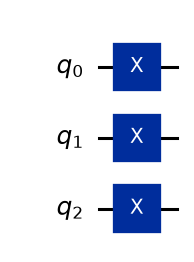

In [4]:
flip = QuantumCircuit(3)  # One qubit, initially |0>
flip.x(0)                 # Flip qubit 0 to |1>
flip.x(1)                 # Flip qubit 0 to |1>
flip.x(2)                 # Flip qubit 0 to |1>
flip.draw("mpl")

### Measure and execute

Measurement in the computational basis returns an ordinary bit, 0 or 1. After an ideal measurement, the qubit is in the basis state corresponding to the result. Measuring it again immediately in the same basis gives the same result. Qiskit stores the recorded bit in a **classical register**. `measure_all()` adds measurements and, here, creates a register named `meas`.

A **shot** is one fresh preparation and execution of the entire circuit followed by measurement. It is **not** repeated measurement of one unchanged prepared state.

We copy the circuit before adding measurements so the original remains available for later calculations.

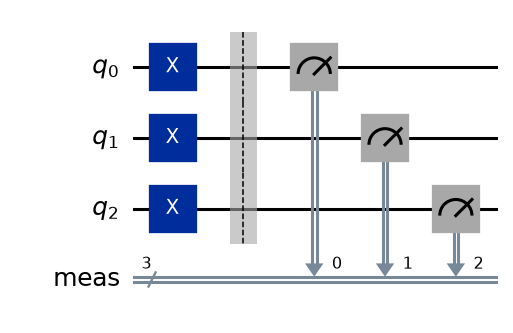

{'111': 1024}


In [5]:
flip_measured = flip.copy()
flip_measured.measure_all()
display(flip_measured.draw("mpl"))

sampler = StatevectorSampler(seed=SEED)
job = sampler.run([flip_measured], shots=SHOTS)
result = job.result()
flip_counts = result[0].data.meas.get_counts()
print(flip_counts)

**Expected:** `{'1': 1024}`. This is a dictionary of **counts**.

Read the result expression once:

| Part | Meaning |
|---|---|
| `result[0]` | Result for the first circuit in our input list |
| `.data.meas` | Measurement data for the register called `meas` |
| `.get_counts()` | Convert measurement outcomes to a counts dictionary |

`StatevectorSampler` is an ideal simulator using the **Sampler V2 interface**. A seed makes its simulated random samples reproducible. Use `seed=None` when you want fresh randomness. Our circuits put measurements only at the end; this sampler does not support mid-circuit measurements.

### A small reusable helper

The following function packages exactly the execution steps above. For the rest of this notebook, pass it a circuit **without measurements or classical bits**. It measures a copy, leaving your original untouched.

In [6]:
def sample(circuit, shots=SHOTS, seed=SEED):
    """Sample a circuit with no existing measurements or classical bits."""
    if circuit.num_clbits:
        raise ValueError("Pass the original circuit before adding measurements.")
    measured = circuit.copy()
    measured.measure_all()
    job = StatevectorSampler(seed=seed).run([measured], shots=shots)
    return job.result()[0].data.meas.get_counts()

zero = QuantumCircuit(1)
print("Do nothing:", sample(zero))
print("Apply X:", sample(flip))

Do nothing: {'0': 1024}
Apply X: {'111': 1024}


### Exercise 1 · Undo a flip 

Modify the starter below to apply **two X gates**. Predict the outcome before running it.

<details><summary>Hint</summary>
An X gate reverses the action of another X gate. Add one more <code>undo.x(0)</code> before sampling.
</details>

The starter is valid code, but it does not yet solve the exercise. Recreate the circuit each time you run the cell so gates do not accidentally accumulate.

In [8]:
undo = QuantumCircuit(1)
undo.x(0) # Starting with 0, flipping to 1
undo.x(0) # Starting from 1, flipping to 0
print("Your circuit:", sample(undo)) # Expecting 0 SHOTS times

Your circuit: {'0': 1024}


## 3 · Superposition and sampling

A qubit state can be written

$$|\psi\rangle=\alpha|0\rangle+\beta|1\rangle,
\qquad |\alpha|^2+|\beta|^2=1.$$

The numbers $\alpha$ and $\beta$ are **amplitudes**. They can be **negative or complex**. Measurement returns 0 with probability $|\alpha|^2$ and 1 with probability $|\beta|^2$.

The **Hadamard gate**, abbreviated H, creates this equal superposition from zero:

$$H|0\rangle=|+\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}}.$$

**Predict:** what histogram would you expect from many independent shots?

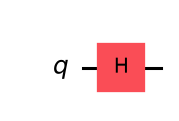

{'0': 474, '1': 550}


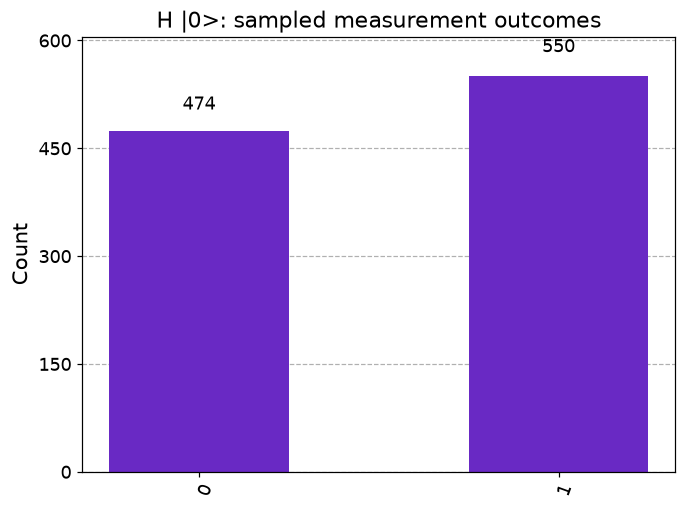

In [ ]:
plus = QuantumCircuit(1)
plus.h(0)
display(plus.draw("mpl"))
plus_counts = sample(plus)
# Expecting a 50/50 chance of 0> or 1>, but quantum systems are inherently probabilistic. Should get 50/50 over several samples.
print(plus_counts)
plot_histogram(plus_counts, title="H |0>: sampled measurement outcomes", color="#6929c4")

**Expected:** approximately half 0 and half 1. A finite run need not split exactly evenly. The histogram's vertical axis shows counts. Divide a count by the total number of shots to estimate its probability.

### Exact prediction versus finite data

`Statevector` lets a simulator inspect the amplitudes **before measurement**. A real device does not return its full statevector in one shot.

In [12]:
plus_state = Statevector.from_instruction(plus)
print(f"Amplitudes [0: {np.round(plus_state.data, 4)[0]}, 1: {np.round(plus_state.data, 4)[1]}")
print("Exact probabilities:", np.round(plus_state.probabilities(), 4))

Amplitudes [0: (0.7071+0j), 1: (0.7071+0j)
Exact probabilities: [0.5 0.5]


Each amplitude is about $0.7071=1/\sqrt{2}$; squaring its magnitude gives $0.5$.

### Exercise 2 · How many shots are enough?

Run the cell below. Change the shot numbers or the seed. What changes, and what stays the same?

In [14]:
for n_shots in [20, 200, 2000]:
    counts = sample(plus, shots=n_shots, seed=17)
    fraction_one = counts.get("1", 0) / n_shots
    print(f"{n_shots:4d} shots: fraction of 1s = {fraction_one:.3f}")

  20 shots: fraction of 1s = 0.450
 200 shots: fraction of 1s = 0.495
2000 shots: fraction of 1s = 0.487


The theoretical probability stays at $1/2$. Typical sampling fluctuations get smaller with more shots, roughly as $1/\sqrt{N}$. A particular larger run is **not guaranteed** to be closer to $1/2$ than every smaller run.

> A 50/50 histogram alone cannot tell a coherent superposition from a classical random preparation of 0 and 1. To see the difference, we need another operation before measuring.

## 4 · Interference: why phase matters

Think of amplitudes as quantities that can reinforce or cancel. The second action of H is

$$H|1\rangle=|-\rangle=\frac{|0\rangle-|1\rangle}{\sqrt{2}}.$$

The minus sign matters when we combine amplitudes. Applying H twice to zero gives

$$H(H|0\rangle)
=\frac{H|0\rangle+H|1\rangle}{\sqrt{2}}
=\frac{(|0\rangle+|1\rangle)+(|0\rangle-|1\rangle)}{2}
=|0\rangle.$$

The two contributions to 1 cancel; the contributions to 0 reinforce. This is **interference**.

**Vote before running:** after H then H, will we see only 0, only 1, or a 50/50 split?

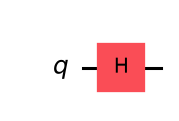

H then H: {'0': 474, '1': 550}


In [ ]:
hh = QuantumCircuit(1)
hh.h(0)
hh.h(0)  # No measurement between these gates
display(hh.draw("mpl"))
print("H then H:", sample(hh))

### A Z gate changes relative phase

$$Z|0\rangle=|0\rangle,\qquad Z|1\rangle=-|1\rangle.$$

Consequently, $Z|+\rangle=|-\rangle$. Both $|+\rangle$ and $|-\rangle$ still give 50/50 results in the computational basis. Their **relative sign** becomes visible if we apply H before measurement.

A sign multiplying the **whole state** is a global phase and does not change measurement predictions. The sign on just one component is a relative phase.

**Predict:** what will H, then Z, then H produce from $|0\rangle$?

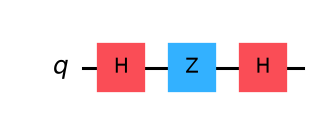

H then Z; measure directly: {'0': 474, '1': 550}
H then Z then H: {'1': 1024}


In [ ]:
minus = QuantumCircuit(1)
minus.h(0) # + state
minus.z(0) # - state

# z|+> = (z|0> - |->) / sqrt(2) = | - >

hzh = minus.copy()
hzh.h(0)
display(hzh.draw("mpl"))
print("H then Z; measure directly:", sample(minus))
print("H then Z then H:", sample(hzh))

**Expected:** H–Z gives roughly 50/50; H–Z–H gives only 1. H has converted an otherwise hidden relative phase into a detectable population difference.

### Superposition versus ordinary randomness

Compare two preparations, then apply a final H:

| Preparation before the final H | Output after final H |
|---|---|
| Coherent $|+\rangle$ | Always 0 |
| Randomly prepare $|0\rangle$ or $|1\rangle$, each with probability 1/2 | 50/50 |

The next cell computes the random preparation by averaging the probabilities of its two possible inputs. It is a classical mixture, not a superposition of those preparations.

In [ ]:

random_zero_branch = QuantumCircuit(1)
random_zero_branch.h(0)  # Prepare 0, then apply H

random_one_branch = QuantumCircuit(1)
random_one_branch.x(0)  # Prepare 1
random_one_branch.h(0) # Then apply H

mixture_probabilities = (
    0.5 * Statevector.from_instruction(random_zero_branch).probabilities()
    + 0.5 * Statevector.from_instruction(random_one_branch).probabilities()
)
print("Coherent +, then H:", np.round(Statevector.from_instruction(hh).probabilities(), 3))
print("Random 0 or 1, then H:", np.round(mixture_probabilities, 3))

Coherent +, then H: [1. 0.]
Random 0 or 1, then H: [0.5 0.5]


### Checkpoint 

Explain to a partner: “Why is H not just a classical random coin flip?”

**Key idea:** a superposition retains relative-phase information that later gates can use. Measurement statistics from a single basis do not reveal all of that information.

## 5 · Two qubits and entanglement

Two qubits have four computational basis states: $|00\rangle, |01\rangle, |10\rangle, |11\rangle$. In our examples, the displayed string is **q₁q₀**: **qubit 0 is the rightmost character**. In the circuit drawing, qubit 0 is the **top wire**.

This statement assumes our direct mapping from each qubit to the correspondingly numbered classical bit, created by `measure_all()`.

**Predict:** flip only qubit 0. Will the output string be `01` or `10`?

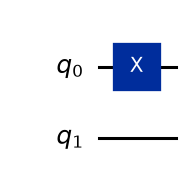

{'01': 1000}


In [18]:
# Size of state space = 2^n where n is the number of qubits
# qiskit uses little endian
ordering = QuantumCircuit(2)
ordering.x(0)
display(ordering.draw("mpl"))
print(sample(ordering, shots=1000))

### The controlled-X gate

`qc.cx(control, target)` flips the target when the control is 1. It acts coherently on superpositions; it does not measure the control.

For `cx(0, 1)`, qubit 0 controls qubit 1:

| Input q₁q₀ | Output q₁q₀ |
|---|---|
| 00 | 00 |
| 01 | 11 |
| 10 | 10 |
| 11 | 01 |

The filled dot marks the control; the circled plus marks the X target. A CX gate does not entangle every possible input. Now combine it with H.

### Create a Bell state

Starting from $|00\rangle$, H on qubit 0 followed by CX gives

$$|00\rangle\xrightarrow{H_0}
\frac{|00\rangle+|01\rangle}{\sqrt{2}}
\xrightarrow{\mathrm{CX}_{0\to1}}
\frac{|00\rangle+|11\rangle}{\sqrt{2}}=|\Phi^+\rangle.$$

**Predict:** which bitstrings should occur, and which should never occur in an ideal run?

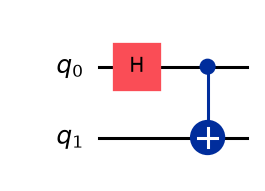

{'00': 474, '11': 550}


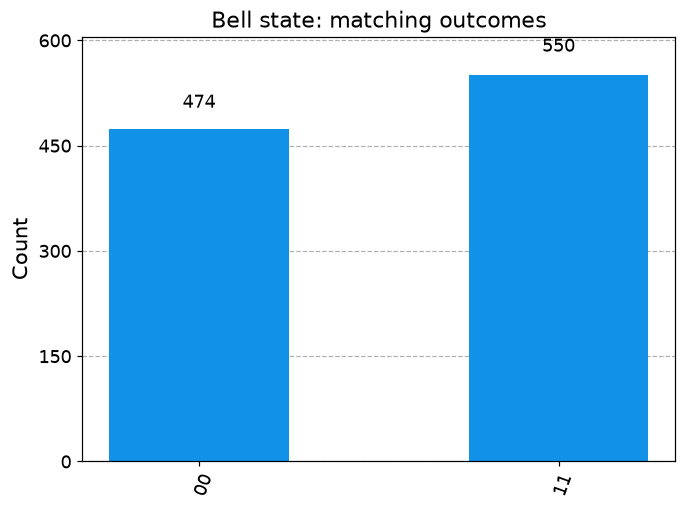

In [20]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
display(bell.draw("mpl"))
bell_counts = sample(bell)
print(bell_counts)
plot_histogram(bell_counts, title="Bell state: matching outcomes", color="#1192e8")

**Expected:** only `00` and `11`, roughly equally often. Each qubit's individual result is random, but the two results agree.

This pure state is **entangled**: it cannot be written as a separate state for qubit 0 multiplied by a separate state for qubit 1. In contrast, H on each qubit independently prepares $|+\rangle|+\rangle$, a product state.

Independent superpositions: {'00': 229, '10': 275, '01': 245, '11': 275}


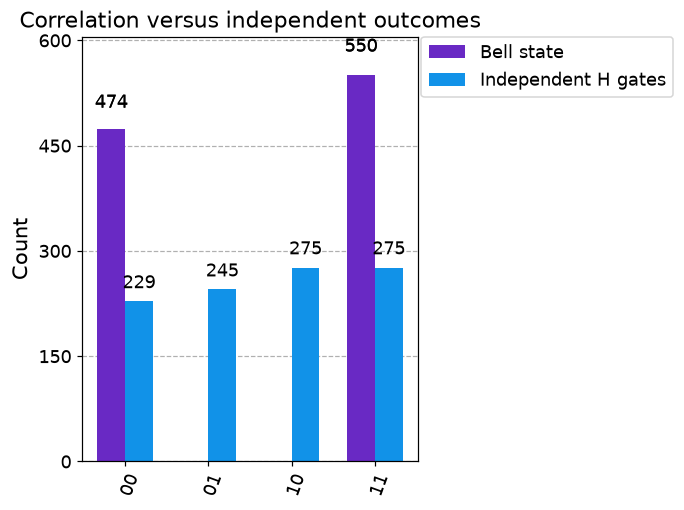

In [21]:
independent = QuantumCircuit(2)
independent.h(0)
independent.h(1)
independent_counts = sample(independent)
print("Independent superpositions:", independent_counts)
plot_histogram(
    [bell_counts, independent_counts],
    legend=["Bell state", "Independent H gates"],
    title="Correlation versus independent outcomes",
    color=["#6929c4", "#1192e8"],
)

### Correlation alone is not an entanglement test

A classical source can also generate matching `00` and `11` outcomes by tossing one coin and copying its result. That source has the same computational-basis histogram as the Bell state.

Applying H to both qubits before measuring means measuring in the **X basis**. In this basis, our Bell state still gives matching outcomes; the classical 50/50 mixture of $|00\rangle$ and $|11\rangle$ gives all four outcomes equally often. This distinguishes these two candidate preparations. It is not a loophole-free Bell test.

In [18]:
bell_x_basis = bell.copy()
bell_x_basis.h(0)
bell_x_basis.h(1)
print("Bell state, X-basis readout:", sample(bell_x_basis))

# Each classical branch becomes uniform after applying H to both qubits.
branch_00 = QuantumCircuit(2)
branch_00.h(0)
branch_00.h(1)
branch_11 = QuantumCircuit(2)
branch_11.x(0)
branch_11.x(1)
branch_11.h(0)
branch_11.h(1)
classical_x_probabilities = (
    Statevector.from_instruction(branch_00).probabilities()
    + Statevector.from_instruction(branch_11).probabilities()
) / 2
print("Classical mixture, X basis [00, 01, 10, 11]:", classical_x_probabilities)

Bell state, X-basis readout: {'00': 474, '11': 550}
Classical mixture, X basis [00, 01, 10, 11]: [0.25 0.25 0.25 0.25]


Entanglement does **not** let either participant choose the other's random outcome or send a message faster than light.

### Exercise 3 · Make the results disagree 

Add one X gate to the Bell preparation so that only `01` and `10` occur. Does flipping either qubit work? Predict before editing.

In [19]:
opposite = bell.copy()
# TODO: add an X gate on one qubit before measurement.
print("Your circuit:", sample(opposite))
# Goal: only 01 and 10, roughly equally often.

Your circuit: {'00': 474, '11': 550}


## 6 · Mini-project: three qubits and a bit flip

Work in pairs. One person edits; the other predicts. Then switch roles.

### Part A · Build a GHZ state 

Prepare

$$|\mathrm{GHZ}\rangle=\frac{|000\rangle+|111\rangle}{\sqrt{2}}.$$

1. Create a circuit with three qubits.
2. Use one H and two CX gates to correlate all three.
3. Draw the circuit and sample it.
4. Explain why only two of the eight possible strings appear.

<details><summary>Hint</summary>
Start with the Bell circuit on qubits 0 and 1. Then use <code>cx(1, 2)</code> or <code>cx(0, 2)</code> to include qubit 2.
</details>

In [34]:
# GHZ shows a superposition and entanglement
ghz = QuantumCircuit(3)
ghz.h(1)
ghz.cx(1, 0)
ghz.cx(1, 2)
# TODO: add one H gate and two CX gates.
print("Your circuit:", sample(ghz))
# Goal: only 000 and 111, roughly equally often.

Your circuit: {'000': 474, '111': 550}


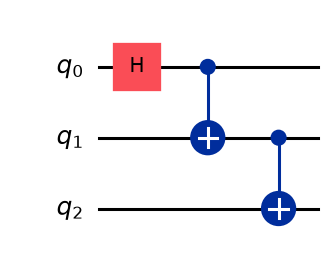

Reference GHZ: {'000': 474, '111': 550}


In [36]:
ghz = QuantumCircuit(3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(1, 2)
display(ghz.draw("mpl"))
ghz_counts = sample(ghz)
print("Reference GHZ:", ghz_counts)

### Part B · Flip one qubit

The output order is **q₂q₁q₀**. Apply X to qubit 2 after preparing GHZ.

Before running, write down the two expected output strings. Then change `error_qubit` to 0 or 1 and repeat. This is an **intentional error on every shot**, not a realistic random noise model.

X on qubit 2: {'011': 474, '100': 550}


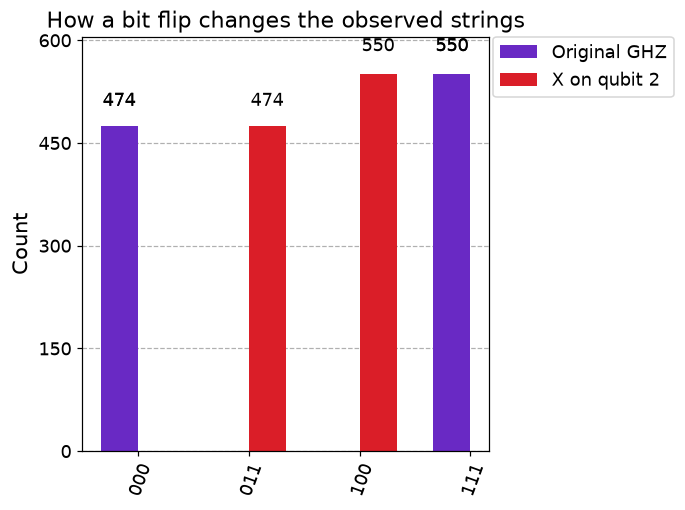

In [37]:
error_qubit = 2  # Try 0 and 1 after predicting each result.
ghz_with_error = ghz.copy()
ghz_with_error.x(error_qubit)
error_counts = sample(ghz_with_error)
print(f"X on qubit {error_qubit}:", error_counts)
plot_histogram(
    [ghz_counts, error_counts],
    legend=["Original GHZ", f"X on qubit {error_qubit}"],
    title="How a bit flip changes the observed strings",
    color=["#6929c4", "#da1e28"],
)

### Part C · A connection to error correction 

For X on qubit 2, the two outcomes become `100` and `011`. Both violate the original “all three bits agree” pattern.

Comparing neighboring bits gives two **parity checks**. XOR, written `^` for Python integers, is 0 when two bits match and 1 when they differ.

| Single bit flip after GHZ preparation | Possible output strings | (q₀ XOR q₁, q₁ XOR q₂) |
|---|---|---|
| None | 000, 111 | (0, 0) |
| X on q₀ | 001, 110 | (1, 0) |
| X on q₁ | 010, 101 | (1, 1) |
| X on q₂ | 100, 011 | (0, 1) |

Under the assumption of **at most one X error**, these parities identify its location without depending on whether the original outcome was `000` or `111`.

In [38]:
for bitstring in sorted(error_counts):
    q2, q1, q0 = [int(bit) for bit in bitstring]
    checks = (q0 ^ q1, q1 ^ q2)
    print(bitstring, "-> parity checks", checks)

011 -> parity checks (0, 1)
100 -> parity checks (0, 1)


## 7 · From this simulator to quantum hardware

Our experiments followed **build → execute → analyze**. On a real device, add compilation and account setup:

| Stage | What changes on a QPU |
|---|---|
| Prepare access | Use an IBM Quantum account and the appropriate runtime package |
| Build | Express the computation as a circuit |
| Compile / transpile | Map qubits and gates to the device's supported gates and connectivity |
| Execute | Submit the compiled circuit to a hardware execution service and collect shots |
| Analyze | Compare the observed distribution with an ideal prediction and account for uncertainty |

**Transpilation** preserves the intended ideal computation while rewriting its implementation. Actual devices introduce gate and readout errors; their results need not match our ideal simulation. More shots reduce sampling uncertainty, but do not automatically remove device errors.

Today's `StatevectorSampler` is local software. It does not secretly submit a job to IBM or access a QPU. The full statevector is a simulation aid, not a directly available hardware output. General statevector simulation needs $2^n$ amplitudes for $n$ qubits, so it cannot scale indefinitely on a laptop.

For a subsequent hardware session, follow the official [run your first circuit on hardware](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/hello-world) guide.

## 8 · Recap and exit ticket

Without running code, explain:

1. Starting from zero, why does H–H produce 0, while H–Z–H produces 1?
2. With three qubits and `measure_all()`, which qubit is 1 in the string `001`?
3. What changes in a Bell circuit's histogram when you add X on one qubit?

**Take into the hackathon:** build the smallest circuit that tests your idea; predict its ideal result; run it; check bit order; then change one thing at a time. Keep the circuit, package versions, shot count, and seed with your results.

| Tool | Use |
|---|---|
| `QuantumCircuit(n)` | Start an n-qubit circuit |
| `.x(q)` | Flip basis states |
| `.h(q)` | Create superposition or change measurement basis |
| `.z(q)` | Change relative phase |
| `.cx(control, target)` | Apply a controlled flip |
| `.draw('mpl')` | Draw the circuit |
| `.measure_all()` | Add measurements into classical bits |
| `StatevectorSampler` | Sample ideal measurement outcomes |
| `Statevector.from_instruction(qc)` | Inspect a simulated state before measurement |
| `plot_histogram(counts)` | Visualize observed frequencies |

## Answers to the core exercises

Try each exercise before reading its solution.

**Exercise 1:** X followed by X restores zero.

In [24]:
undo_solution = QuantumCircuit(1)
undo_solution.x(0)
undo_solution.x(0)
print(sample(undo_solution))

{'0': 1024}


**Exercise 2:** the exact probability is unchanged; the sampled fraction varies. Using more shots generally improves statistical precision. Reusing the same seed and settings reproduces the simulated result.

**Exercise 3:** flip either qubit after preparing the Bell state.

In [57]:
opposite_solution = bell.copy()
opposite_solution.x(0)
print(sample(opposite_solution))

{'01': 483, '10': 541}


**GHZ:** one solution is H on qubit 0, CX(0,1), then CX(1,2), as in the reference cell. CX(0,2) can replace the second CX.

**Exit ticket:** (1) H recombines amplitudes; the intervening Z changes which outcome cancels. (2) Qubit 0. (3) Matching `00`/`11` outcomes become opposite `01`/`10` outcomes, each still with probability 1/2 in the ideal state.

## Appendix A · A tunable quantum coin 

H gave us an equal superposition. A rotation `ry(theta, qubit)` lets us vary the probabilities continuously:

$$R_y(\theta)|0\rangle=\cos(\theta/2)|0\rangle+\sin(\theta/2)|1\rangle,
\qquad P(1)=\sin^2(\theta/2).$$

Angles are in **radians**: $\pi$ radians equals 180 degrees. Try $0$, $\pi/2$, and $\pi$. Predict first.

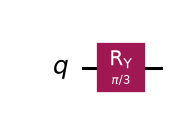

Exact P(1): 0.24999999999999994
Observed fraction: 0.256


In [39]:
theta = np.pi / 3
coin = QuantumCircuit(1)
coin.ry(theta, 0)
display(coin.draw("mpl"))
coin_counts = sample(coin, shots=2000)
print("Exact P(1):", np.sin(theta / 2) ** 2)
print("Observed fraction:", coin_counts.get("1", 0) / 2000)

A **parameter** is a symbolic placeholder. Bind it to numerical values before execution. Parameterized circuits are useful in optimization: a classical program can change angles, run a circuit, and compare the results.

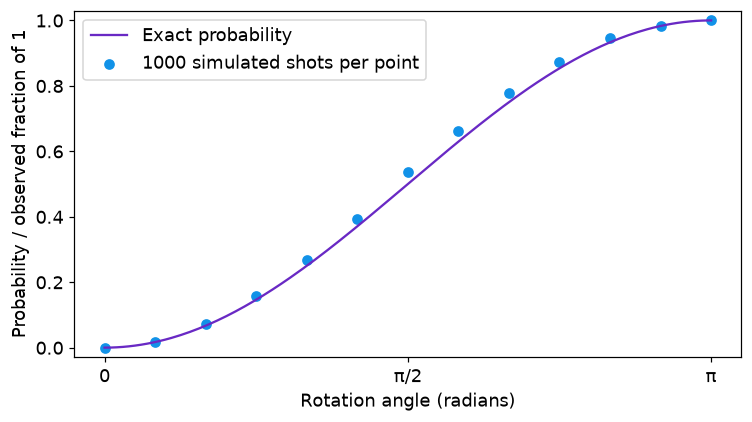

In [40]:
from qiskit.circuit import Parameter

angle = Parameter("theta")
tunable_coin = QuantumCircuit(1)
tunable_coin.ry(angle, 0)
# print(tunable_coin)

angles = np.linspace(0, np.pi, 13)
observed = []
for value in angles:
    bound_coin = tunable_coin.assign_parameters({angle: value})
    counts = sample(bound_coin, shots=1000)
    observed.append(counts.get("1", 0) / 1000)

smooth_angles = np.linspace(0, np.pi, 200)
plt.figure(figsize=(7, 4))
plt.plot(smooth_angles, np.sin(smooth_angles / 2) ** 2,
         color="#6929c4", label="Exact probability")
plt.scatter(angles, observed, color="#1192e8", label="1000 simulated shots per point")
plt.xlabel("Rotation angle (radians)")
plt.ylabel("Probability / observed fraction of 1")
plt.xticks([0, np.pi / 2, np.pi], ["0", "π/2", "π"])
plt.ylim(-0.03, 1.03)
plt.legend()
plt.tight_layout()
plt.show()

**Challenge:** choose an angle that makes $P(1)=1/4$. One answer is $\theta=\pi/3$, since $\sin^2(\pi/6)=1/4$.

## Appendix B · Reveal a phase error using an expectation value 

An **expectation value** is an average numerical measurement result. To measure Pauli X, apply a Hadamard gate before the usual computational-basis measurement, the resulting measurement outputs are $\langle + | X| + \rangle=+1$ and $\langle - | X| - \rangle=-1$.

The GHZ state has $\langle GHZ | XXX| GHZ \rangle=+1$. A Z gate on one qubit changes the relative sign between $|000\rangle$ and $|111\rangle$, making $\langle GHZ| XXX |GHZ\rangle=-1$. The ordinary computational-basis probabilities remain unchanged.

This requires no new simulator package. **Sampler** returns sampled bitstrings; **Estimator** returns expectation values. `StatevectorEstimator` gives exact expectation values for these unitary, noiseless circuits, up to floating-point rounding. Hardware estimates would have sampling uncertainty and device error.

In [42]:
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp

ghz_phase_error = ghz.copy()
ghz_phase_error.z(0)
xxx = SparsePauliOp("XXX")
estimator = StatevectorEstimator()
expectations = estimator.run([(ghz, xxx), (ghz_phase_error, xxx)]).result()

print("Original GHZ, <XXX>:", float(expectations[0].data.evs))
print("After Z on q0, <XXX>:", float(expectations[1].data.evs))
print("Same Z-basis probabilities?", np.allclose(
    Statevector.from_instruction(ghz).probabilities(),
    Statevector.from_instruction(ghz_phase_error).probabilities(),
))

Original GHZ, <XXX>: 0.9999999999999998
After Z on q0, <XXX>: -0.9999999999999998
Same Z-basis probabilities? True


To relate this to bitstrings, apply H to every qubit before measuring. Each `1` is an X-basis −1 outcome, so the product is $(-1)^{\text{number of 1s}}$.

In [43]:
for label, preparation in [("Original", ghz), ("Z error", ghz_phase_error)]:
    readout = preparation.copy()
    for qubit in range(3):
        readout.h(qubit)
    counts = sample(readout)
    parity_average = sum(
        ((-1) ** bits.count("1")) * count for bits, count in counts.items()
    ) / sum(counts.values())
    print(label, counts, "-> sampled <XXX> =", parity_average)

Original {'000': 229, '101': 275, '011': 245, '110': 275} -> sampled <XXX> = 1.0
Z error {'001': 229, '100': 275, '010': 245, '111': 275} -> sampled <XXX> = -1.0


**Expected:** the original GHZ gives even-parity strings and the phase-flipped GHZ gives odd-parity strings. This reveals a change that the earlier Z-basis histogram missed. A single stabilizer measurement by itself is not full quantum state tomography or a full error-correction protocol.

## Official references and follow-up reading

The lesson's explanations and exercises are written for this workshop. API conventions and workflows were checked against official documentation on **23 November 2026**.

1. [Install Qiskit](https://quantum.cloud.ibm.com/docs/en/qiskit/install-qiskit) — environments and installation.
2. [Qiskit quickstart](https://quantum.cloud.ibm.com/docs/en/guides/quick-start) — the circuit–sampler–counts workflow.
3. [Bit ordering](https://quantum.cloud.ibm.com/docs/en/qiskit/bit-ordering) — wire order, string order, and control/target conventions.
4. [StatevectorSampler API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler) — seeds, shots, results, and simulator limitations.
5. [Statevector API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector) — exact states and probabilities.
6. [StatevectorEstimator API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator) — expectation values.
7. [Deutsch's algorithm](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/deutsch-algorithm) — oracle queries and phase kickback.
8. [Run your first circuit on hardware](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/hello-world) — hardware access and execution.
